# 03 · Segmentation and recommendation

Notebook 02 explained what drives loss ratios **in general**. This notebook decides **which treaties to act on**, which
is what a pricing team needs at renewal. It ends by writing `outputs/treaty_results.csv`, the only file the dashboard reads.

*Synthetic data; no client data used.*

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN = ROOT / "data" / "treaty_year_clean.csv"
OUT = ROOT / "outputs"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
if not CLEAN.exists():
    raise FileNotFoundError("Run notebooks/01_eda.ipynb first: it writes data/treaty_year_clean.csv")

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150)
    plt.show()

df = pd.read_csv(CLEAN)

## 1. One row per treaty: the last three years

Current performance matters more than 2016, so each treaty is judged on its **latest three years**. The three-year loss
ratio is **total claims ÷ total premium** over those years, not an average of three yearly ratios, so a small year does not
count as much as a big one.

In [2]:
last3 = df.sort_values("year").groupby("treaty_id").tail(3)
attrs = (df.drop_duplicates("treaty_id").set_index("treaty_id")
           [["cedent_name", "line_of_business", "treaty_type", "region", "inception_year", "commission_pct"]])

treaty = (last3.groupby("treaty_id")
               .agg(years_used=("year", "size"), first_year=("year", "min"), last_year=("year", "max"),
                    premium_3y=("premium_earned", "sum"), claims_3y=("claims_paid", "sum"),
                    expenses_3y=("expense_amount", "sum"))
               .join(attrs))
treaty["avg_loss_ratio"] = treaty.claims_3y / treaty.premium_3y
treaty["annual_premium"] = treaty.premium_3y / treaty.years_used
treaty["annual_claims"] = treaty.claims_3y / treaty.years_used

print(treaty.years_used.value_counts().to_string())
print(f"{len(treaty)} treaties; three-year portfolio loss ratio {treaty.claims_3y.sum() / treaty.premium_3y.sum():.3f}")

years_used
3    155
155 treaties; three-year portfolio loss ratio 0.857


Every treaty has three full years (2023-2025), so all are compared on the same footing.

## 2. Worst ten and best ten by loss ratio

In [3]:
cols = ["cedent_name", "line_of_business", "treaty_type", "avg_loss_ratio", "annual_premium"]
print("WORST TEN by loss ratio")
display(treaty.sort_values("avg_loss_ratio", ascending=False)[cols].head(10))
print("BEST TEN by loss ratio")
display(treaty.sort_values("avg_loss_ratio")[cols].head(10))

WORST TEN by loss ratio


,cedent_name,line_of_business,treaty_type,avg_loss_ratio,annual_premium
treaty_id,,,,,
TR0031,Harbourview Life,Income Protection,Surplus,1.166,"982,047.653"
TR0120,Granite Belt Mutual,Income Protection,Excess of Loss,1.164,"6,975,586.743"
TR0151,Pelican Bay Life,TPD,Quota Share,1.114,"308,808.417"
TR0142,Bluegum Assurance,Income Protection,Excess of Loss,1.109,"714,854.937"
TR0015,Harbourview Life,TPD,Quota Share,1.103,"15,993,388.527"
TR0048,Granite Belt Mutual,Income Protection,Quota Share,1.082,"54,720,250.910"
TR0071,Kookaburra Life,Income Protection,Surplus,1.059,"4,181,278.777"
TR0025,Southern Star Life,Trauma,Quota Share,1.056,"106,543.937"
TR0040,Wattle Mutual,Trauma,Excess of Loss,1.052,"2,242,800.507"


BEST TEN by loss ratio


,cedent_name,line_of_business,treaty_type,avg_loss_ratio,annual_premium
treaty_id,,,,,
TR0073,Coolabah Insurance,TPD,Quota Share,0.461,"166,379.233"
TR0053,Granite Belt Mutual,Death,Quota Share,0.467,"421,865.490"
TR0104,Banksia Life,Death,Excess of Loss,0.492,"588,496.407"
TR0011,Cape Otway Assurance,Trauma,Quota Share,0.513,"3,154,780.923"
TR0112,Wattle Mutual,Death,Surplus,0.520,"2,254,295.417"
TR0109,Silver Wattle Insurance,Death,Quota Share,0.562,"1,200,279.223"
TR0007,Harbourview Life,Death,Excess of Loss,0.575,"568,361.320"
TR0093,Southern Star Life,Death,Quota Share,0.576,"10,362,090.950"
TR0139,Granite Belt Mutual,Death,Quota Share,0.590,"5,371,801.247"


Six of the worst ten are Income Protection and seven of the best ten are Death cover, as notebook 02 predicts.
But a ratio says nothing about **how much money** is at stake.

## 3. Weight by size: dollars lost

**Dollars lost** = claims paid in excess of premium, per year = (loss ratio − 1.0) × annual premium, floored at zero.
A small treaty at 1.4 can lose less money than a large one at 1.05.

In [4]:
treaty["dollars_lost"] = ((treaty.avg_loss_ratio - 1.0) * treaty.annual_premium).clip(lower=0)

worst_ratio = treaty.sort_values("avg_loss_ratio", ascending=False).head(10)
worst_money = treaty.sort_values("dollars_lost", ascending=False).head(10)
print("WORST TEN by dollars lost")
display(worst_money[cols + ["dollars_lost"]])

both = worst_ratio.index.intersection(worst_money.index)
print(f"In both top-ten lists: {len(both)}")
print("Worst by ratio but not by money:", ", ".join(worst_ratio.index.difference(worst_money.index)))
print("Worst by money but not by ratio:", ", ".join(worst_money.index.difference(worst_ratio.index)))
total_lost = treaty.dollars_lost.sum()
print(f"\nTotal dollars lost: ${total_lost / 1e6:,.2f}m a year across {(treaty.dollars_lost > 0).sum()} treaties")

WORST TEN by dollars lost


,cedent_name,line_of_business,treaty_type,avg_loss_ratio,annual_premium,dollars_lost
treaty_id,,,,,,
TR0048,Granite Belt Mutual,Income Protection,Quota Share,1.082,"54,720,250.910","4,460,240.417"
TR0015,Harbourview Life,TPD,Quota Share,1.103,"15,993,388.527","1,646,256.997"
TR0120,Granite Belt Mutual,Income Protection,Excess of Loss,1.164,"6,975,586.743","1,146,546.733"
TR0012,Silver Wattle Insurance,Income Protection,Excess of Loss,1.023,"18,932,230.543","426,510.643"
TR0116,Jacaranda Life,Income Protection,Quota Share,1.044,"8,783,407.293","387,104.087"
TR0149,Mallee Life,Income Protection,Surplus,1.023,"10,933,761.233","251,119.623"
TR0071,Kookaburra Life,Income Protection,Surplus,1.059,"4,181,278.777","248,454.980"
TR0031,Harbourview Life,Income Protection,Surplus,1.166,"982,047.653","163,496.147"
TR0128,Brolga Assurance,Trauma,Surplus,1.011,"11,183,582.247","122,752.130"


In both top-ten lists: 7
Worst by ratio but not by money: TR0025, TR0142, TR0151
Worst by money but not by ratio: TR0012, TR0128, TR0149

Total dollars lost: $9.22m a year across 17 treaties


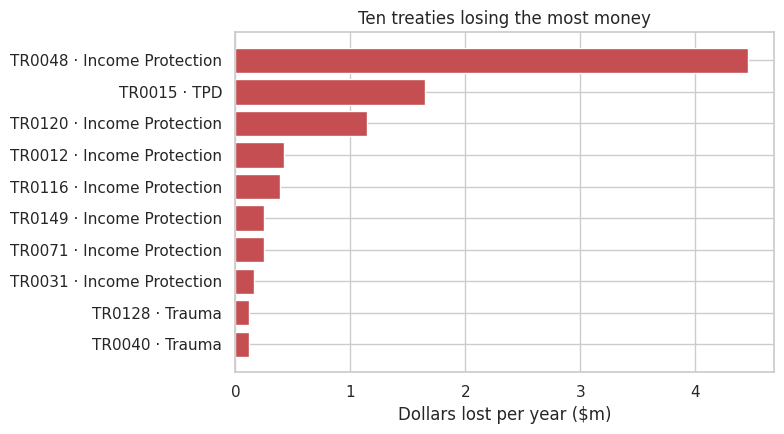

In [5]:
plot = worst_money.sort_values("dollars_lost")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(plot.index + " · " + plot.line_of_business, plot.dollars_lost / 1e6, color="#C44E52")
ax.set(xlabel="Dollars lost per year ($m)", title="Ten treaties losing the most money")
save_fig("12_worst_by_dollars")

Seven treaties are on both lists; three swap out. **TR0025, TR0142 and TR0151 have bad ratios but are small**, so they
cost little. **TR0012, TR0128 and TR0149 have ratios only just above 1.0 but are large**, so they cost more. That is
the gap between a *ratio* problem and a *money* problem, and it changes the renewal priorities. The loss is also highly
concentrated: one treaty, **TR0048**, loses about $4.5m a year on its own, about half the total.

*Cross-check:* this top ten matches `sql/03_worst_performers.sql` exactly, treaty for treaty and dollar for dollar.

### The full-cost view

Dollars lost above counts claims only. The reinsurer also pays **commission** back to the cedent and carries **expenses**,
so a treaty's real break-even loss ratio is 1 − commission % − expense ratio.

In [6]:
treaty["breakeven_loss_ratio"] = 1 - treaty.commission_pct - treaty.expenses_3y / treaty.premium_3y
treaty["full_cost_result"] = (treaty.premium_3y * (1 - treaty.commission_pct) - treaty.claims_3y
                              - treaty.expenses_3y) / treaty.years_used
losing_full = treaty.full_cost_result < 0
print(f"Median full-cost break-even loss ratio: {treaty.breakeven_loss_ratio.median():.3f}")
print(f"Treaties losing money on claims alone: {(treaty.dollars_lost > 0).sum()} of {len(treaty)}")
print(f"Treaties losing money once commission and expenses are included: {losing_full.sum()} of {len(treaty)}")
print(f"Full-cost loss on those treaties: ${-treaty.loc[losing_full, 'full_cost_result'].sum() / 1e6:,.1f}m a year")

Median full-cost break-even loss ratio: 0.726
Treaties losing money on claims alone: 17 of 155
Treaties losing money once commission and expenses are included: 103 of 155
Full-cost loss on those treaties: $151.3m a year


On a full-cost basis the problem is far wider: **two-thirds of treaties do not cover claims, commission and expenses**.
The rest of this notebook keeps the claims-only measure as the headline because it is the clear-cut, uncontroversial
loss. Commission and expense levels are negotiable terms, which makes the full-cost picture an argument for reviewing
commission on the weakest lines, not just repricing individual treaties.

## 4. Bands

Thresholds come from this portfolio's numbers, not round figures:

| Band | Three-year loss ratio | Why this threshold | Action |
|---|---|---|---|
| Profitable | below 0.72 | 0.72 is the median **full-cost break-even**: below it a typical treaty covers claims, commission and expenses | Renew as is |
| Watch | 0.72 to 0.90 | Covers claims but probably not all costs | Monitor, review pricing |
| Underperforming | 0.90 to 1.00 | 0.90 is about the **75th percentile**: the worst quarter of the book, close to losing on claims alone | Reprice at renewal |
| Critical | 1.00 and above | **Claims exceed premium**: losing money before any cost | Restructure or exit |

Check the thresholds against the distribution:
0.250   0.690
0.500   0.791
0.750   0.910
0.900   1.007


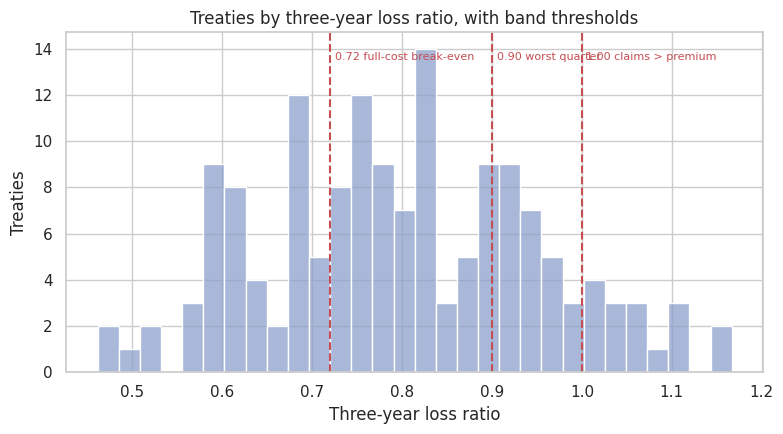

,treaties,annual_premium_m,dollars_lost_m,action
band,,,,
Profitable,48,162.082,0.000,Renew as is
Watch,64,392.840,0.000,"Monitor, review pricing"
Underperforming,26,230.782,0.000,Reprice at renewal
Critical,17,158.097,9.218,Restructure or exit


In [7]:
BANDS = ["Profitable", "Watch", "Underperforming", "Critical"]
ACTIONS = {"Profitable": "Renew as is", "Watch": "Monitor, review pricing",
           "Underperforming": "Reprice at renewal", "Critical": "Restructure or exit"}
treaty["band"] = pd.cut(treaty.avg_loss_ratio, [0, 0.72, 0.90, 1.00, np.inf], right=False, labels=BANDS)
treaty["action"] = treaty.band.map(ACTIONS)

print("Check the thresholds against the distribution:")
print(treaty.avg_loss_ratio.quantile([0.25, 0.5, 0.75, 0.9]).round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(treaty.avg_loss_ratio, bins=30, ax=ax, color="#8DA0CB")
for x, label in [(0.72, "0.72 full-cost break-even"), (0.90, "0.90 worst quarter"), (1.00, "1.00 claims > premium")]:
    ax.axvline(x, color="#C44E52", linestyle="--", linewidth=1.5)
    ax.text(x + 0.005, ax.get_ylim()[1] * 0.92, label, fontsize=8, color="#C44E52")
ax.set(xlabel="Three-year loss ratio", ylabel="Treaties", title="Treaties by three-year loss ratio, with band thresholds")
save_fig("13_band_thresholds")

summary = treaty.groupby("band", observed=True).agg(
    treaties=("avg_loss_ratio", "size"), annual_premium_m=("annual_premium", lambda s: s.sum() / 1e6),
    dollars_lost_m=("dollars_lost", lambda s: s.sum() / 1e6))
summary["action"] = summary.index.map(ACTIONS)
summary

## 5. Where do the bad bands concentrate?

line_of_business,Death,TPD,Trauma,Income Protection
band,,,,
Profitable,32,6,4,6
Watch,13,14,21,16
Underperforming,5,6,7,8
Critical,0,2,5,10


treaty_type,Quota Share,Surplus,Excess of Loss
band,,,
Profitable,31,7,10
Watch,37,20,7
Underperforming,8,13,5
Critical,6,6,5


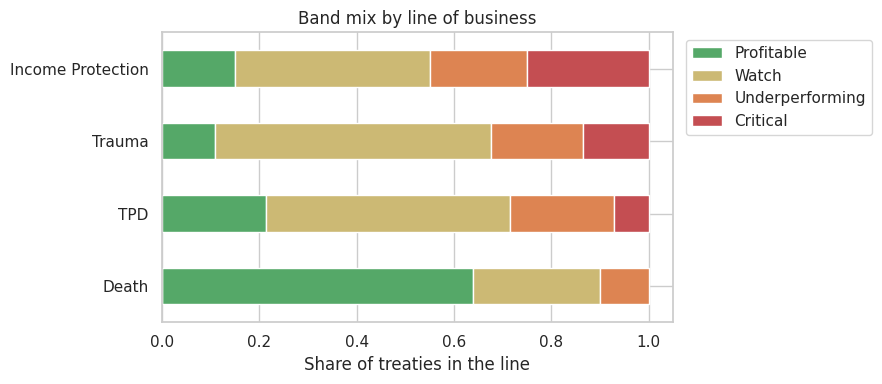

In [8]:
by_line = pd.crosstab(treaty.band, treaty.line_of_business)[["Death", "TPD", "Trauma", "Income Protection"]]
display(by_line)
display(pd.crosstab(treaty.band, treaty.treaty_type)[["Quota Share", "Surplus", "Excess of Loss"]])

share = pd.crosstab(treaty.line_of_business, treaty.band, normalize="index").loc[["Death", "TPD", "Trauma", "Income Protection"]]
ax = share.plot(kind="barh", stacked=True, figsize=(9, 4),
                color=["#55A868", "#CCB974", "#DD8452", "#C44E52"])
ax.set(xlabel="Share of treaties in the line", ylabel="", title="Band mix by line of business")
ax.legend(title="", bbox_to_anchor=(1.01, 1), loc="upper left")
save_fig("14_bands_by_line")

**The headline:** not one Death treaty is Critical, and 32 of 50 are Profitable. **Income Protection has 10 of the 17
Critical treaties**, and only 6 of its 40 treaties are Profitable. Trauma is the second problem line (5 Critical).
By treaty type the Critical band is spread evenly, so structure is a secondary issue next to line of business, which
matches the regression.

## 6. Write the dashboard's input

In [9]:
results = (treaty.reset_index()
           [["treaty_id", "cedent_name", "line_of_business", "treaty_type", "region", "inception_year",
             "avg_loss_ratio", "annual_premium", "annual_claims", "dollars_lost",
             "breakeven_loss_ratio", "full_cost_result", "band", "action"]]
           .sort_values("avg_loss_ratio", ascending=False))
results["band"] = results.band.astype(str)
for c in ["avg_loss_ratio", "breakeven_loss_ratio"]:
    results[c] = results[c].round(6)
for c in ["annual_premium", "annual_claims", "dollars_lost", "full_cost_result"]:
    results[c] = results[c].round(0)

results.to_csv(OUT / "treaty_results.csv", index=False)
print(f"Wrote outputs/treaty_results.csv: {len(results)} treaties, {results.shape[1]} columns")
results.head()

Wrote outputs/treaty_results.csv: 155 treaties, 14 columns


,treaty_id,cedent_name,line_of_business,treaty_type,region,inception_year,avg_loss_ratio,annual_premium,annual_claims,dollars_lost,breakeven_loss_ratio,full_cost_result,band,action
30,TR0031,Harbourview Life,Income Protection,Surplus,NSW,2016,1.166,"982,048.000","1,145,544.000","163,496.000",0.785,"-374,436.000",Critical,Restructure or exit
119,TR0120,Granite Belt Mutual,Income Protection,Excess of Loss,NSW,2015,1.164,"6,975,587.000","8,122,133.000","1,146,547.000",0.669,"-3,457,090.000",Critical,Restructure or exit
150,TR0151,Pelican Bay Life,TPD,Quota Share,QLD,2017,1.114,"308,808.000","344,108.000","35,300.000",0.776,"-104,376.000",Critical,Restructure or exit
141,TR0142,Bluegum Assurance,Income Protection,Excess of Loss,WA,2015,1.109,"714,855.000","793,020.000","78,166.000",0.788,"-229,512.000",Critical,Restructure or exit
14,TR0015,Harbourview Life,TPD,Quota Share,VIC,2014,1.103,"15,993,389.000","17,639,646.000","1,646,257.000",0.799,"-4,855,120.000",Critical,Restructure or exit


## 7. Recommendation

In [10]:
critical = treaty[treaty.band == "Critical"].sort_values("dollars_lost", ascending=False)
top3 = critical.head(3)
ip_critical = critical[critical.line_of_business == "Income Protection"]
print(f"Critical treaties: {len(critical)}, losing ${critical.dollars_lost.sum() / 1e6:.1f}m a year")
print(f"Income Protection among them: {len(ip_critical)}, losing ${ip_critical.dollars_lost.sum() / 1e6:.1f}m")
print(f"Top three ({', '.join(top3.index)}): ${top3.dollars_lost.sum() / 1e6:.1f}m, "
      f"{top3.dollars_lost.sum() / treaty.dollars_lost.sum():.0%} of the total")
for tid, r in top3.iterrows():
    print(f"  {tid} {r.cedent_name}, {r.line_of_business} {r.treaty_type}: loss ratio {r.avg_loss_ratio:.3f}, "
          f"premium ${r.annual_premium / 1e6:.1f}m, needs about +{r.avg_loss_ratio - 1:.0%} on premium to break even on claims")

Critical treaties: 17, losing $9.2m a year
Income Protection among them: 10, losing $7.2m
Top three (TR0048, TR0015, TR0120): $7.3m, 79% of the total
  TR0048 Granite Belt Mutual, Income Protection Quota Share: loss ratio 1.082, premium $54.7m, needs about +8% on premium to break even on claims
  TR0015 Harbourview Life, TPD Quota Share: loss ratio 1.103, premium $16.0m, needs about +10% on premium to break even on claims
  TR0120 Granite Belt Mutual, Income Protection Excess of Loss: loss ratio 1.164, premium $7.0m, needs about +16% on premium to break even on claims


**Seventeen treaties lose money on claims alone, costing about $9.2m a year, and ten of them are Income Protection,
accounting for $7.2m.** The loss is concentrated: three treaties (TR0048 and TR0120 from Granite Belt Mutual, both Income
Protection, and TR0015 from Harbourview Life, TPD) account for 79% of it, and TR0048 alone, a $55m-a-year treaty,
needs only about an 8% rate increase to stop losing money on claims. **Reprice those three at renewal first**, put the
remaining fourteen Critical treaties (eight Income Protection, five Trauma) through a restructure-or-exit review, and
leave Death cover as it is. Because two-thirds of treaties fail to cover their full costs, the pricing team should
also review commission terms on Income Protection and Trauma across the book, not only treaty by treaty.

*Limitations:* synthetic data; three years is a short window for small, volatile treaties (notebook 01, Figure 6), so
a small treaty in the Critical band should be confirmed with its longer history before exiting it.

## 8. Looking ahead: a 2026 forecast

Everything above explains the past. A pricing team also wants to know **which treaties are likely to lose money next
year**. The regression from notebook 02 can be used for that, but a forecast has to be tested differently.
Notebook 02 used a random split because it was explaining. A forecast must be tested the way it will be used:
**train only on earlier years, then predict a later year it has never seen.**

In [11]:
import json

import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score

formula = ("loss_ratio ~ C(line_of_business, Treatment('Death')) + treaty_age + large_claim_count + log_policies"
           " + C(treaty_type, Treatment('Quota Share')) + cession_pct + C(region, Treatment('NSW'))")
df["log_policies"] = np.log(df.policies_in_force)
past, future = df[df.year <= 2024].copy(), df[df.year == 2025].copy()
bt_model = smf.ols(formula, data=past).fit()

# Large claims are not known in advance, so use each treaty's own average up to 2024
avg_large = past.groupby("treaty_id").large_claim_count.mean()
future["large_claim_count"] = future.treaty_id.map(avg_large).fillna(past.large_claim_count.mean())
future["predicted"] = bt_model.predict(future)

# Two simple alternatives the model has to beat
own_last3 = (past.sort_values("year").groupby("treaty_id").tail(3).groupby("treaty_id")[["claims_paid", "premium_earned"]].sum())
future["own_history"] = future.treaty_id.map(own_last3.claims_paid / own_last3.premium_earned)
rmse = lambda pred: float(np.sqrt(((future.loss_ratio - pred) ** 2).mean()))
backtest = pd.DataFrame({"2025 RMSE": [rmse(past.loss_ratio.mean()), rmse(future.own_history), rmse(future.predicted)]},
                        index=["Portfolio average", "Treaty's own last three years", "Regression"])
backtest

,2025 RMSE
Portfolio average,0.257
Treaty's own last three years,0.265
Regression,0.224


Ranking which treaties lost money in 2025 (AUC, 0.5 = coin toss): regression 0.72, own history 0.57
Predicted share losing money 16.1%, actual 22.6%


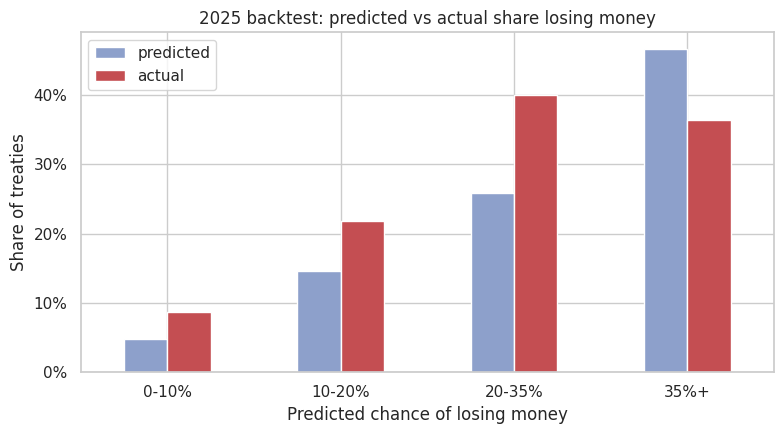

,treaties,predicted,actual
bin,,,
0-10%,58,0.049,0.086
10-20%,46,0.146,0.217
20-35%,40,0.258,0.400
35%+,11,0.467,0.364


In [12]:
# Turn each prediction into a chance of losing money, using residuals from treaties of similar size
bt_resid = pd.DataFrame({"r": bt_model.resid, "pol": past.policies_in_force})
bt_edges = np.quantile(past.policies_in_force, [0, 0.2, 0.4, 0.6, 0.8, 1.0])
size_band = lambda pol: np.clip(np.searchsorted(bt_edges, pol, side="right") - 1, 0, 4)
bt_resid["band"] = size_band(bt_resid.pol)
future["chance_of_loss"] = [(pred + bt_resid.r[bt_resid.band == size_band(pol)] > 1).mean()
                            for pred, pol in zip(future.predicted, future.policies_in_force)]
future["lost_money"] = future.loss_ratio > 1

auc_model = roc_auc_score(future.lost_money, future.chance_of_loss)
auc_own = roc_auc_score(future.lost_money, future.own_history)
print(f"Ranking which treaties lost money in 2025 (AUC, 0.5 = coin toss): "
      f"regression {auc_model:.2f}, own history {auc_own:.2f}")
print(f"Predicted share losing money {future.chance_of_loss.mean():.1%}, actual {future.lost_money.mean():.1%}")

calibration = (future.assign(bin=pd.cut(future.chance_of_loss, [0, 0.1, 0.2, 0.35, 1], include_lowest=True,
                                        labels=["0-10%", "10-20%", "20-35%", "35%+"]))
               .groupby("bin", observed=True)
               .agg(treaties=("lost_money", "size"), predicted=("chance_of_loss", "mean"), actual=("lost_money", "mean")))
ax = calibration[["predicted", "actual"]].plot(kind="bar", figsize=(8, 4.5), color=["#8DA0CB", "#C44E52"], rot=0)
ax.set(xlabel="Predicted chance of losing money", ylabel="Share of treaties",
       title="2025 backtest: predicted vs actual share losing money")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
save_fig("15_forecast_backtest")
calibration

**The forecast is worth having, with one caveat.**

- **Accuracy.** Trained only on 2016-2024, the regression predicted 2025 loss ratios more accurately than either simple
  rule: an RMSE of 0.224 against 0.257 for the portfolio average and 0.265 for each treaty's own recent history, about
  **13% better**.
- **Ranking.** It ranks well: an AUC of about 0.72 for picking out the treaties that lost money, against 0.57 when you
  just assume last year's bad treaties stay bad.
- **The caveat: it is too optimistic.** It predicted about 16% of treaties would lose money in 2025 and 23% did, and in
  the middle bands the actual share runs above the predicted one. The book keeps ageing and getting worse, faster than a
  model fitted on earlier years assumes.
- **How to use it.** Treat the 2026 probabilities as a **ranking of risk**, not exact odds, and expect the true numbers
  to be somewhat higher.

### The 2026 forecast for every treaty

In [13]:
coefs = pd.read_csv(OUT / "model_coefficients.csv").fillna({"level": ""})
summary = json.loads((OUT / "model_summary.json").read_text())
resid = pd.read_csv(OUT / "model_residuals.csv")
edges = np.array(summary["size_band_edges"])
band_of = lambda pol: np.clip(np.searchsorted(edges, pol, side="right") - 1, 0, 4)
resid["band"] = band_of(resid.policies_in_force)

def c(feature, level=""):
    row = coefs[(coefs.feature == feature) & (coefs.level == level)]
    return float(row.coefficient.iloc[0]) if len(row) else 0.0   # reference levels have no row: effect 0

latest = df[df.year == 2025].set_index("treaty_id")
fc = pd.DataFrame(index=latest.index)
fc["treaty_age_2026"] = 2026 - latest.inception_year
fc["expected_large_claims"] = df.groupby("treaty_id").large_claim_count.mean()   # each treaty's long-run average
fc["policies_in_force"] = latest.policies_in_force
fc["expected_premium"] = latest.premium_earned
fc["expected_loss_ratio"] = [
    c("intercept") + c("line_of_business", r.line_of_business) + c("treaty_type", r.treaty_type)
    + c("region", r.region) + c("treaty_age") * age + c("large_claim_count") * lc
    + c("log_policies") * np.log(pol) + c("cession_pct") * r.cession_pct
    for r, age, lc, pol in zip(latest.itertuples(), fc.treaty_age_2026, fc.expected_large_claims, fc.policies_in_force)]

outcomes = [pred + resid.residual[resid.band == band_of(pol)] for pred, pol in zip(fc.expected_loss_ratio, fc.policies_in_force)]
fc["chance_of_loss"] = [(o > 1).mean() for o in outcomes]
fc["expected_shortfall"] = [np.maximum(o - 1, 0).mean() * prem for o, prem in zip(outcomes, fc.expected_premium)]
fc["expected_band"] = pd.cut(fc.expected_loss_ratio, [0, 0.72, 0.90, 1.00, np.inf], right=False, labels=BANDS).astype(str)

forecast = (treaty[["cedent_name", "line_of_business", "treaty_type", "region", "avg_loss_ratio", "band"]]
            .rename(columns={"avg_loss_ratio": "current_loss_ratio", "band": "current_band"})
            .join(fc).reset_index().sort_values("chance_of_loss", ascending=False))
forecast["current_band"] = forecast.current_band.astype(str)
order = {b: i for i, b in enumerate(BANDS)}
forecast["moving_to_worse_band"] = forecast.expected_band.map(order) > forecast.current_band.map(order)
for col in ["expected_loss_ratio", "chance_of_loss", "current_loss_ratio", "expected_large_claims"]:
    forecast[col] = forecast[col].round(4)
forecast["expected_premium"] = forecast.expected_premium.round(0)
forecast["expected_shortfall"] = forecast.expected_shortfall.round(0)
forecast.to_csv(OUT / "treaty_forecast.csv", index=False)

(OUT / "forecast_backtest.json").write_text(json.dumps({
    "rmse_regression": rmse(future.predicted), "rmse_portfolio_average": rmse(past.loss_ratio.mean()),
    "rmse_own_history": rmse(future.own_history), "auc_regression": float(auc_model), "auc_own_history": float(auc_own),
    "predicted_share_losing": float(future.chance_of_loss.mean()), "actual_share_losing": float(future.lost_money.mean()),
}, indent=2))

print(f"Wrote outputs/treaty_forecast.csv ({len(forecast)} treaties) and outputs/forecast_backtest.json")
print(f"More likely than not to lose money in 2026: {(forecast.chance_of_loss > 0.5).sum()} treaties")
print(f"Expected claims shortfall across the book: ${forecast.expected_shortfall.sum() / 1e6:.1f}m")
print(f"Treaties expected to move into a worse band: {forecast.moving_to_worse_band.sum()}")
forecast[["treaty_id", "cedent_name", "line_of_business", "treaty_type", "current_loss_ratio",
          "expected_loss_ratio", "chance_of_loss", "expected_shortfall"]].head(10)

Wrote outputs/treaty_forecast.csv (155 treaties) and outputs/forecast_backtest.json
More likely than not to lose money in 2026: 4 treaties
Expected claims shortfall across the book: $21.0m
Treaties expected to move into a worse band: 45


,treaty_id,cedent_name,line_of_business,treaty_type,current_loss_ratio,expected_loss_ratio,chance_of_loss,expected_shortfall
0,TR0001,Kookaburra Life,Income Protection,Excess of Loss,0.959,1.071,0.672,"421,316.000"
70,TR0071,Kookaburra Life,Income Protection,Surplus,1.059,1.065,0.656,"387,026.000"
125,TR0126,Wattle Mutual,Trauma,Surplus,0.912,1.055,0.650,"913,169.000"
119,TR0120,Granite Belt Mutual,Income Protection,Excess of Loss,1.164,1.061,0.645,"623,654.000"
31,TR0032,Coral Coast Assurance,Trauma,Surplus,0.965,1.013,0.489,"503,746.000"
141,TR0142,Bluegum Assurance,Income Protection,Excess of Loss,1.109,1.034,0.449,"86,171.000"
129,TR0130,Kestrel Insurance,Income Protection,Excess of Loss,0.832,0.992,0.441,"1,655,363.000"
73,TR0074,Harbourview Life,Income Protection,Surplus,0.875,0.989,0.378,"109,636.000"
60,TR0061,Harbourview Life,Trauma,Excess of Loss,0.938,0.973,0.371,"386,199.000"
127,TR0128,Brolga Assurance,Trauma,Surplus,1.011,0.976,0.371,"596,319.000"


**What the 2026 forecast says**

- **Expected claims shortfall: about $21m.** Income Protection accounts for about $12m of it and Trauma about $6m.
  Death cover contributes very little. The line-of-business story holds going forward.
- **Four treaties are more likely than not to lose money:** TR0001, TR0071 and TR0120 (all Income Protection) and
  TR0126 (Trauma). Their chances are 65-67%.
- **The biggest expected loss is not on today's Critical list.** TR0060, an Income Protection treaty with about $78m of
  premium, is currently only Underperforming, but its size makes it the largest single expected shortfall (about
  $1.9m). Big treaties near break-even deserve as much attention as small ones far above it.
- **Today's worst treaties are expected to partly recover.** Only 3 of the 17 Critical treaties are expected to stay
  Critical, because part of a bad three years is large-claim luck that does not repeat (regression to the mean).
  Meanwhile **45 treaties are expected to slip into a worse band** as the book ages. Repricing decisions should weigh
  both lists, not only the current one.

Given the backtest, read these as a ranking of risk; the true probabilities are probably somewhat higher.